# CS781 · Phase 1 · Submission 01

## Architecture

## Dependencies

In [1]:
import os
import sys
import time
import subprocess
from pathlib import Path

SESSION_START = time.monotonic()
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q',
                'tokenizers==0.23.2', 'huggingface_hub==1.33.0', 'ijson==3.5.1',
                'rouge-score==0.1.2', 'sacrebleu==2.5.1'], check=True)
os.environ['TOKENIZERS_PARALLELISM'] = 'true'
os.environ['RAYON_NUM_THREADS'] = '2'
os.environ['OMP_NUM_THREADS'] = '2'
os.environ['HF_HUB_DISABLE_PROGRESS_BARS'] = '1'
os.environ['PYTORCH_CUDA_ALLOC_CONF'] = 'expandable_segments:True'

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.8/51.8 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 69.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 846.4/846.4 kB 31.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 149.9/149.9 kB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 104.1/104.1 kB 5.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.6/129.6 kB 4.7 MB/s eta 0:00:00


## Hugging Face token

In [2]:
import torch
os.environ["HF_TOKEN"] = os.environ["HF_TOKEN"]

## Configuration

In [ ]:
import json

RUN_NAME = 'phase1_s01_legalrope204m'
OUT = Path('/kaggle/working') / RUN_NAME
OUT.mkdir(parents=True, exist_ok=True)
os.chdir(OUT)

CFG = {
    'output': str(OUT), 'repo': 'Exploration-Lab/CS-781-Capstone',
    'dataset_revision': None, 'seed': 42,
    'source_mix': {'high_courts': 0.45, 'supreme_court': 0.35, 'acts': 0.10, 'tribunals': 0.10},
    'corpus_tokens': 1200000000, 'train_tokens': 450000000,
    'val_tokens_per_source': 250000, 'dev_examples_per_source': 16,
    'tokenizer_chars_per_source': 12000000, 'vocab_size': 32000,
    'dim': 896, 'heads': 14, 'layers': 18, 'ffn_dim': 2432,
    'seq_len': 1536, 'context': 2048, 'gradient_checkpointing': False,
    'sequences_per_gpu': 16, 'lr': 1.5e-4, 'min_lr': 1.5e-5,
    'weight_decay': 0.1, 'warmup_steps': 150, 'grad_clip': 1.0,
    'train_hours': 10.0, 'session_hours': 11.0, 'calibration_steps': 20,
    'log_every': 100, 'eval_every': 100, 'save_every': 100, 'eval_tokens': 262144,
    'generation_batch_size': 8, 'max_generation_tokens': 2048,
    'decoding_candidates': [
        {'name': 'greedy', 'temperature': 0.0, 'top_p': 1.0, 'repetition_penalty': 1.08},
        {'name': 'sample070', 'temperature': 0.7, 'top_p': 0.92, 'repetition_penalty': 1.08},
        {'name': 'sample080_rep120', 'temperature': 0.8, 'top_p': 0.95, 'repetition_penalty': 1.2},
    ],
}
(OUT / 'config.json').write_text(json.dumps(CFG, indent=2))
print('Output:', OUT)

Output: /kaggle/working/phase1_s01_legalrope204m


## Model and training modules

In [34]:
%%writefile model.py
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.checkpoint import checkpoint


class RMSNorm(nn.Module):
    def __init__(self, dim, eps=1e-5):
        super().__init__()
        self.weight = nn.Parameter(torch.ones(dim))
        self.eps = eps

    def forward(self, x):
        y = x.float()
        y = y * torch.rsqrt(y.square().mean(-1, keepdim=True) + self.eps)
        return y.to(x.dtype) * self.weight


class Attention(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        d = cfg['dim']
        self.heads = cfg['heads']
        self.head_dim = d // self.heads
        self.qkv = nn.Linear(d, 3 * d, bias=False)
        self.out = nn.Linear(d, d, bias=False)
        inv = 1.0 / (10000 ** (torch.arange(0, self.head_dim, 2).float() / self.head_dim))
        self.register_buffer('inv_freq', inv, persistent=False)

    def rope(self, x, positions):
        phase = positions.float().unsqueeze(-1) * self.inv_freq.float()
        cos = phase.cos().unsqueeze(1).to(x.dtype)
        sin = phase.sin().unsqueeze(1).to(x.dtype)
        even, odd = x[..., ::2], x[..., 1::2]
        return torch.stack((even * cos - odd * sin, even * sin + odd * cos), -1).flatten(-2)

    def forward(self, x, positions, mask=None, past=None, use_cache=False):
        b, t, d = x.shape
        q, k, v = self.qkv(x).view(b, t, 3, self.heads, self.head_dim).unbind(2)
        q, k, v = (z.transpose(1, 2) for z in (q, k, v))
        q, k = self.rope(q, positions), self.rope(k, positions)
        old = 0
        if past is not None:
            old = past[0].size(2)
            k, v = torch.cat((past[0], k), 2), torch.cat((past[1], v), 2)
        allowed = None
        causal = mask is None and old == 0
        if mask is not None or old:
            key_idx = torch.arange(k.size(2), device=x.device)
            query_idx = old + torch.arange(t, device=x.device)
            allowed = key_idx[None, :] <= query_idx[:, None]
            allowed = allowed[None, None, :, :]
            if mask is not None:
                allowed = allowed & mask[:, None, None, :].bool()
        y = F.scaled_dot_product_attention(q, k, v, attn_mask=allowed,
                                          dropout_p=0.0, is_causal=causal)
        y = self.out(y.transpose(1, 2).contiguous().view(b, t, d))
        return y, (k, v) if use_cache else None


class Block(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        d, f = cfg['dim'], cfg['ffn_dim']
        self.norm1, self.norm2 = RMSNorm(d), RMSNorm(d)
        self.attn = Attention(cfg)
        self.gate = nn.Linear(d, f, bias=False)
        self.up = nn.Linear(d, f, bias=False)
        self.down = nn.Linear(f, d, bias=False)

    def forward(self, x, positions, mask=None, past=None, use_cache=False):
        a, cache = self.attn(self.norm1(x), positions, mask, past, use_cache)
        x = x + a
        z = self.norm2(x)
        return x + self.down(F.silu(self.gate(z)) * self.up(z)), cache


class LegalLM(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.cfg = dict(cfg)
        self.embed = nn.Embedding(cfg['vocab_size'], cfg['dim'])
        self.blocks = nn.ModuleList([Block(cfg) for _ in range(cfg['layers'])])
        self.norm = RMSNorm(cfg['dim'])
        self.apply(self._init)
        for block in self.blocks:
            nn.init.normal_(block.attn.out.weight, std=0.02 / math.sqrt(2 * cfg['layers']))
            nn.init.normal_(block.down.weight, std=0.02 / math.sqrt(2 * cfg['layers']))

    @staticmethod
    def _init(module):
        if isinstance(module, (nn.Linear, nn.Embedding)):
            nn.init.normal_(module.weight, std=0.02)

    def forward(self, ids, targets=None, attention_mask=None, past=None,
                use_cache=False, last_only=False):
        old = 0 if past is None else past[0][0].size(2)
        if attention_mask is None:
            positions = torch.arange(old, old + ids.size(1), device=ids.device)[None, :]
        else:
            positions = (attention_mask.long().cumsum(-1) - 1).clamp_min(0)[:, -ids.size(1):]
        x, caches = self.embed(ids), []
        for i, block in enumerate(self.blocks):
            if self.training and self.cfg.get('gradient_checkpointing', False):
                x = checkpoint(lambda z, m=block: m(z, positions)[0], x, use_reentrant=False)
            else:
                x, cache = block(x, positions, attention_mask,
                                 None if past is None else past[i], use_cache)
                if use_cache:
                    caches.append(cache)
        x = self.norm(x)
        if targets is not None:
            h, y = x.flatten(0, 1), targets.flatten()
            total = h.new_zeros((), dtype=torch.float32)
            for a in range(0, h.size(0), 256):
                def part(z, labels):
                    return F.cross_entropy(F.linear(z, self.embed.weight).float(), labels, reduction='sum')
                if self.training:
                    loss = checkpoint(part, h[a:a+256], y[a:a+256], use_reentrant=False)
                else:
                    loss = part(h[a:a+256], y[a:a+256])
                total = total + loss
            return total / y.numel()
        logits = F.linear(x[:, -1:] if last_only else x, self.embed.weight)
        return logits, caches if use_cache else None

Overwriting model.py


### Data and BPE

In [35]:
%%writefile prepare.py
import hashlib
import itertools
import json
import os
import random
from pathlib import Path
import ijson
import numpy as np
from huggingface_hub import HfApi, HfFileSystem
from tokenizers import Tokenizer, models, pre_tokenizers, decoders, trainers


def fingerprint(text):
    return hashlib.blake2b(' '.join(text.split()).encode(), digest_size=16).hexdigest()


def is_validation(digest):
    return int(digest[:8], 16) % 100 == 0


def records(stream):
    first = stream.read(4096).lstrip()[:1]
    stream.seek(0)
    if first == b'[':
        rows = ijson.items(stream, 'item')
    else:
        rows = (v for _, v in ijson.kvitems(stream, ''))
    for row in rows:
        text = row if isinstance(row, str) else row['text']
        if text.strip():
            yield text


def shuffled(iterator, seed, size=256):
    rng = random.Random(seed)
    buffer = list(itertools.islice(iterator, size))
    for item in iterator:
        j = rng.randrange(len(buffer))
        yield buffer[j]
        buffer[j] = item
    rng.shuffle(buffer)
    yield from buffer


def main():
    cfg = json.loads(Path('config.json').read_text())
    out = Path(cfg['output'])
    data = out / 'data'
    data.mkdir(parents=True, exist_ok=True)
    api = HfApi(token=os.environ['HF_TOKEN'])
    revision = cfg.get('dataset_revision') or api.dataset_info(cfg['repo']).sha
    names = api.list_repo_files(cfg['repo'], repo_type='dataset', revision=revision)
    sources = {}
    for source in cfg['source_mix']:
        matches = [p for p in names if p.endswith('/train_' + source + '.json')
                   and p.startswith('Phase_1_Pretraining/Train/')]
        sources[source] = matches[0]
    tests = [p for p in names if p.startswith('Phase_1_Pretraining/Test/') and p.lower().endswith('.json')]
    manifest_base = {'revision': revision, 'sources': sources, 'test_file': tests[0],
                     'seed': cfg['seed'], 'source_mix': cfg['source_mix'],
                     'corpus_tokens': cfg['corpus_tokens'], 'val_tokens_per_source': cfg['val_tokens_per_source'],
                     'vocab_size': cfg['vocab_size'], 'tokenizer_chars_per_source': cfg['tokenizer_chars_per_source']}
    signature = hashlib.sha256(json.dumps(manifest_base, sort_keys=True).encode()).hexdigest()
    done = data / 'manifest.json'
    if done.exists():
        print('Reusing prepared data.', flush=True)
        return
    fs = HfFileSystem(token=os.environ['HF_TOKEN'])

    def stream(source):
        remote = f"datasets/{cfg['repo']}@{revision}/{sources[source]}"
        with fs.open(remote, 'rb', block_size=8 * 1024 * 1024) as f:
            yield from records(f)

    tok_path = out / 'tokenizer.json'
    sample_path = data / 'tokenizer_sample.jsonl'
    seen = set()
    with sample_path.open('w', encoding='utf-8') as writer:
        for si, source in enumerate(sources):
            chars = 0
            for text in shuffled(stream(source), cfg['seed'] + si):
                h = fingerprint(text)
                if is_validation(h) or h in seen:
                    continue
                seen.add(h)
                room = cfg['tokenizer_chars_per_source'] - chars
                sample = text[:min(32768, room)]
                writer.write(json.dumps(sample, ensure_ascii=False) + '\n')
                chars += len(sample)
                if chars >= cfg['tokenizer_chars_per_source']:
                    break
            print(f'Tokenizer sample {source}: {chars:,} characters', flush=True)
    tokenizer = Tokenizer(models.BPE(unk_token='<unk>'))
    tokenizer.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
    tokenizer.decoder = decoders.ByteLevel()
    trainer = trainers.BpeTrainer(vocab_size=cfg['vocab_size'], min_frequency=2,
                                 special_tokens=['<pad>', '<bos>', '<eos>', '<unk>'],
                                 initial_alphabet=pre_tokenizers.ByteLevel.alphabet(), show_progress=True)
    with sample_path.open(encoding='utf-8') as reader:
        tokenizer.train_from_iterator((json.loads(line) for line in reader), trainer=trainer)
    tokenizer.save(str(tok_path))
    eos = tokenizer.token_to_id('<eos>')
    counts = {'train': {}, 'val': {}}
    seen, dev = set(), []
    stats = {}
    for si, source in enumerate(sources):
        limits = {'train': int(cfg['corpus_tokens'] * cfg['source_mix'][source]),
                  'val': cfg['val_tokens_per_source']}
        used = {'train': 0, 'val': 0}
        docs = {'train': 0, 'val': 0}
        handles = {s: (data / f'{source}.{s}.bin.tmp').open('wb') for s in used}
        ndev = 0
        try:
            for text in shuffled(stream(source), cfg['seed'] + si):
                digest = fingerprint(text)
                if digest in seen:
                    continue
                split = 'val' if is_validation(digest) else 'train'
                if used[split] >= limits[split]:
                    if all(used[s] >= limits[s] for s in used):
                        break
                    continue
                seen.add(digest)
                ids = tokenizer.encode(text, add_special_tokens=False).ids + [eos]
                ids = ids[:limits[split] - used[split]]
                np.asarray(ids, dtype=np.uint16).tofile(handles[split])
                used[split] += len(ids)
                docs[split] += 1
                if split == 'val' and ndev < cfg['dev_examples_per_source']:
                    words = text.split()
                    if len(words) >= 640:
                        start = int(digest[8:16], 16) % (len(words) - 639)
                        dev.append({'id': source + '_' + digest, 'source': source,
                                    'prompt': ' '.join(words[start:start+512]),
                                    'reference': ' '.join(words[start+512:start+640])})
                        ndev += 1
                if sum(docs.values()) % 2000 == 0:
                    print(source, used, flush=True)
        finally:
            for f in handles.values():
                f.close()
        for split in used:
            os.replace(data / f'{source}.{split}.bin.tmp', data / f'{source}.{split}.bin')
            counts[split][source] = used[split]
        stats[source] = {'tokens': used, 'documents': docs, 'dev_examples': ndev}
        print(source, stats[source], flush=True)
    (data / 'dev.json').write_text(json.dumps(dev, ensure_ascii=False, indent=2))
    tok_hash = hashlib.sha256(tok_path.read_bytes()).hexdigest()
    manifest = dict(manifest_base, signature=signature, counts=counts, stats=stats,
                    tokenizer_sha256=tok_hash, actual_vocab_size=tokenizer.get_vocab_size(),
                    special_ids={s: tokenizer.token_to_id(s) for s in ['<pad>', '<bos>', '<eos>', '<unk>']})
    done.write_text(json.dumps(manifest, indent=2))
    sample_path.unlink()
    print('Prepared', counts, 'Held-out continuations:', len(dev), flush=True)


if __name__ == '__main__':
    main()

Overwriting prepare.py


### Two-GPU training

In [36]:
%%writefile train.py
import contextlib
import hashlib
import json
import math
import os
import random
import time
from datetime import timedelta
from pathlib import Path
import numpy as np
import torch
import torch.distributed as dist
from torch.nn.parallel import DistributedDataParallel as DDP
from model import LegalLM


def atomic_save(payload, path):
    tmp = str(path) + '.tmp'
    torch.save(payload, tmp)
    os.replace(tmp, path)


class Blocks:
    def __init__(self, cfg, manifest, split):
        self.seq = cfg['seq_len']
        self.names = list(cfg['source_mix'])
        self.arrays = [np.memmap(Path(cfg['output']) / 'data' / f'{s}.{split}.bin',
                                 dtype=np.uint16, mode='r') for s in self.names]
        self.lengths = [(len(a) - 1) // self.seq for a in self.arrays]
        self.ends = np.cumsum(self.lengths)
        self.size = int(self.ends[-1])
        self.seed, self.epoch, self.order = cfg['seed'], None, None

    def batch(self, indexes, device, permute=True):
        rows = []
        for index in indexes:
            epoch, offset = divmod(int(index), self.size)
            if permute:
                if epoch != self.epoch:
                    self.order = np.random.default_rng(self.seed + epoch).permutation(self.size)
                    self.epoch = epoch
                offset = int(self.order[offset])
            source = int(np.searchsorted(self.ends, offset, side='right'))
            local = offset - (int(self.ends[source - 1]) if source else 0)
            start = local * self.seq
            rows.append(np.asarray(self.arrays[source][start:start+self.seq+1], dtype=np.int64))
        batch = torch.from_numpy(np.stack(rows))
        if device.type == 'cuda':
            batch = batch.pin_memory()
        batch = batch.to(device, non_blocking=True)
        return batch[:, :-1], batch[:, 1:]


def optimizer_for(model, cfg):
    params = list(model.parameters())
    groups = [{'params': [p for p in params if p.ndim >= 2], 'weight_decay': cfg['weight_decay']},
              {'params': [p for p in params if p.ndim < 2], 'weight_decay': 0.0}]
    return torch.optim.AdamW(groups, lr=cfg['lr'], betas=(0.9, 0.95), eps=1e-8, fused=True)


def probe(cfg, device):
    import gc
    for checkpointing in (False, True):
        for batch_size in (4, 2, 1):
            model = opt = ids = loss = scaler = None
            try:
                torch.cuda.empty_cache()
                torch.cuda.reset_peak_memory_stats()
                test_cfg = dict(cfg, gradient_checkpointing=checkpointing)
                model = LegalLM(test_cfg).to(device).train()
                opt = optimizer_for(model, cfg)
                scaler = torch.amp.GradScaler('cuda', init_scale=256)
                ids = torch.randint(4, cfg['vocab_size'], (batch_size, cfg['seq_len']+1), device=device)
                with torch.autocast('cuda', dtype=torch.float16):
                    loss = model(ids[:, :-1], targets=ids[:, 1:])
                scaler.scale(loss).backward()
                scaler.unscale_(opt)
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(opt)
                scaler.update()
                torch.cuda.synchronize()
                peak = torch.cuda.max_memory_allocated()
                total = torch.cuda.get_device_properties(device).total_memory
                if peak < total * 0.85:
                    return batch_size, checkpointing, peak / 2**30
            except torch.OutOfMemoryError:
                pass
            finally:
                del model, opt, ids, loss, scaler
                gc.collect()
                torch.cuda.empty_cache()
    raise RuntimeError('The model cannot fit even with checkpointing and batch size 1.')


@torch.no_grad()
def evaluate(raw, val, cfg, rank, world, device):
    raw.eval()
    totals = torch.zeros(len(val.names), 2, device=device, dtype=torch.float64)
    per_source = max(1, cfg['eval_tokens'] // (len(val.names) * cfg['seq_len']))
    for s, count in enumerate(val.lengths):
        take = min(per_source, count)
        chosen = np.random.default_rng(cfg['seed'] + s + 999).choice(count, take, replace=False)
        base = int(val.ends[s - 1]) if s else 0
        selected = (chosen + base)[rank::world]
        for start in range(0, len(selected), cfg['micro_batch']):
            ids, labels = val.batch(selected[start:start+cfg['micro_batch']], device, permute=False)
            with torch.autocast('cuda', dtype=torch.float16):
                loss = raw(ids, targets=labels)
            totals[s, 0] += loss.double() * labels.numel()
            totals[s, 1] += labels.numel()
    dist.all_reduce(totals)
    losses = {name: float(totals[s, 0] / totals[s, 1]) for s, name in enumerate(val.names)}
    weighted = sum(cfg['source_mix'][name] * value for name, value in losses.items())
    raw.train()
    return weighted, losses


def main():
    base_cfg = json.loads(Path('config.json').read_text())
    rank = int(os.environ['RANK'])
    local = int(os.environ['LOCAL_RANK'])
    world = int(os.environ['WORLD_SIZE'])
    torch.cuda.set_device(local)
    device = torch.device('cuda', local)
    dist.init_process_group('nccl', timeout=timedelta(minutes=30))
    torch.set_num_threads(2)
    torch.backends.cuda.matmul.allow_tf32 = False
    out = Path(base_cfg['output'])
    manifest = json.loads((out / 'data' / 'manifest.json').read_text())
    actual_hash = hashlib.sha256((out / 'tokenizer.json').read_bytes()).hexdigest()
    cfg = dict(base_cfg, vocab_size=manifest['actual_vocab_size'])
    count = sum(p.numel() for p in LegalLM(cfg).parameters())
    batch, checkpointing, peak = probe(cfg, device)
    flags = torch.tensor([batch, int(not checkpointing)], device=device)
    dist.all_reduce(flags, op=dist.ReduceOp.MIN)
    cfg['micro_batch'] = int(flags[0].item())
    cfg['gradient_checkpointing'] = not bool(flags[1].item())
    accum = cfg['sequences_per_gpu'] // cfg['micro_batch']
    global_batch = world * cfg['sequences_per_gpu']
    tokens_per_step = global_batch * cfg['seq_len']
    random.seed(cfg['seed'] + rank)
    np.random.seed(cfg['seed'] + rank)
    torch.manual_seed(cfg['seed'])
    torch.cuda.manual_seed(cfg['seed'])
    raw = LegalLM(cfg).to(device)
    optimizer = optimizer_for(raw, cfg)
    scaler = torch.amp.GradScaler('cuda', init_scale=1024)
    train, val = Blocks(cfg, manifest, 'train'), Blocks(cfg, manifest, 'val')
    max_steps = math.ceil(cfg['train_tokens'] / tokens_per_step)
    step, best, target_steps, last_eval = 0, float('inf'), max_steps, -1
    calibrated = False
    resume_file = out / 'last.pt'
    resumed = None
    if resume_file.exists():
        resumed = torch.load(resume_file, map_location='cpu', weights_only=False)
        raw.load_state_dict(resumed['model'])
        optimizer.load_state_dict(resumed['optimizer'])
        scaler.load_state_dict(resumed['scaler'])
        step, best = resumed['step'], resumed['best_loss']
        target_steps, calibrated = max_steps, True
        state = resumed['rng'][rank]
        torch.set_rng_state(state['cpu'])
        torch.cuda.set_rng_state(state['cuda'], device)
        random.setstate(state['python'])
        del resumed
    ddp = DDP(raw, device_ids=[local], broadcast_buffers=False, gradient_as_bucket_view=True)
    run_start, initial_step = time.monotonic(), step
    max_seconds = cfg['train_hours'] * 3600
    if rank == 0:
        (out / 'model_config.json').write_text(json.dumps(cfg, indent=2))
        print(f"Training | parameters: {count:,} | tokens/step: {tokens_per_step:,} | resume step: {step:,} | max steps: {max_steps:,}", flush=True)
    log_path = out / 'training.jsonl'
    skipped = 0

    def save(best_changed=False):
        state = {'cpu': torch.get_rng_state(), 'cuda': torch.cuda.get_rng_state(device),
                 'python': random.getstate()}
        rngs = [None] * world
        dist.all_gather_object(rngs, state)
        if rank == 0:
            payload = {'model': raw.state_dict(), 'optimizer': optimizer.state_dict(),
                       'scaler': scaler.state_dict(), 'step': step, 'best_loss': best,
                       'target_steps': target_steps, 'calibrated': calibrated,
                       'config': cfg, 'rng': rngs, 'world_size': world,
                       'data_signature': manifest['signature'], 'tokenizer_sha256': actual_hash}
            atomic_save(payload, out / 'last.pt')
            if best_changed:
                atomic_save({'model': raw.state_dict(), 'config': cfg, 'step': step,
                             'val_loss': best, 'tokenizer_sha256': actual_hash}, out / 'best.pt')
        dist.barrier()

    while step < target_steps:
        optimizer.zero_grad(set_to_none=True)
        warmup = cfg['warmup_steps']
        if step < warmup:
            lr = cfg['lr'] * (step + 1) / warmup
        else:
            progress = min(1.0, (step - warmup) / max(1, target_steps - warmup - 1))
            lr = cfg['min_lr'] + 0.5 * (cfg['lr'] - cfg['min_lr']) * (1 + math.cos(math.pi * progress))
        for group in optimizer.param_groups:
            group['lr'] = lr
        total_loss = torch.zeros((), device=device)
        for micro in range(accum):
            start = step * global_batch + rank * cfg['sequences_per_gpu'] + micro * cfg['micro_batch']
            ids, labels = train.batch(range(start, start + cfg['micro_batch']), device)
            sync = contextlib.nullcontext() if micro == accum - 1 else ddp.no_sync()
            with sync:
                with torch.autocast('cuda', dtype=torch.float16):
                    loss = ddp(ids, targets=labels)
                total_loss += loss.detach() / accum
                scaler.scale(loss / accum).backward()
        scaler.unscale_(optimizer)
        grad_norm = torch.nn.utils.clip_grad_norm_(raw.parameters(), cfg['grad_clip'])
        old_scale = scaler.get_scale()
        scaler.step(optimizer)
        scaler.update()
        overflow = int(scaler.get_scale() < old_scale)
        check = torch.tensor(overflow, device=device)
        dist.all_reduce(check, op=dist.ReduceOp.MAX)
        if check.item():
            skipped += 1
            if skipped > 25:
                raise FloatingPointError('Repeated FP16 overflows; inspect data and training stability.')
            continue
        step += 1
        elapsed = time.monotonic() - run_start
        if not calibrated and step >= initial_step + cfg['calibration_steps']:
            timing = torch.tensor(elapsed, device=device, dtype=torch.float64)
            dist.all_reduce(timing, op=dist.ReduceOp.MAX)
            seconds_per_step = timing.item() / (step - initial_step)
            affordable = step + int(max(0, max_seconds - timing.item() - 600) * 0.85 / seconds_per_step)
            target_steps = min(max_steps, max(step + 1, affordable))
            calibrated = True
            if rank == 0:
                print(f'Calibrated target: {target_steps:,} steps / {target_steps*tokens_per_step:,} tokens', flush=True)
        stop_flag = torch.tensor(int(elapsed > max_seconds - 180), device=device)
        dist.all_reduce(stop_flag, op=dist.ReduceOp.MAX)
        stop = bool(stop_flag.item()) or step >= target_steps
        log = None
        if step % cfg['log_every'] == 0 or stop:
            dist.all_reduce(total_loss)
            log = {'step': step, 'tokens': step * tokens_per_step, 'train_loss': total_loss.item() / world,
                   'lr': lr, 'grad_norm': float(grad_norm), 'elapsed_hours': elapsed / 3600,
                   'tokens_per_second': (step-initial_step)*tokens_per_step/max(elapsed, 1),
                   'scale': scaler.get_scale(), 'skipped_updates_this_session': skipped}
        if step % cfg['eval_every'] == 0 or stop:
            loss, source_losses = evaluate(raw, val, cfg, rank, world, device)
            if not math.isfinite(loss):
                raise FloatingPointError('Validation loss is non-finite.')
            improved = loss < best
            best = min(best, loss)
            last_eval = step
            log = dict(log or {'step': step, 'tokens': step * tokens_per_step},
                       val_loss=loss, perplexity=math.exp(min(loss, 80)), source_val_losses=source_losses)
            save(improved)
        elif step % cfg['save_every'] == 0:
            save()
        if rank == 0 and log is not None:
            with log_path.open('a') as f:
                f.write(json.dumps(log) + '\n')
            print(' | '.join(f'{k}: {v:.4f}' if isinstance(v, float) else f'{k}: {v}'
                             for k, v in log.items() if k in {'step', 'train_loss', 'val_loss', 'perplexity', 'lr'}), flush=True)
        if stop:
            break
    if not (out / 'best.pt').exists():
        loss, source_losses = evaluate(raw, val, cfg, rank, world, device)
        best = loss
        save(True)
    if rank == 0:
        summary = {'parameters': count, 'completed_steps': step, 'training_tokens': step*tokens_per_step,
                   'target_steps': target_steps, 'best_validation_loss': best,
                   'best_perplexity': math.exp(min(best, 80)), 'training_hours_this_session':
                   (time.monotonic()-run_start)/3600, 'effective_batch_sequences': global_batch,
                   'world_size': world, 'source_mix': cfg['source_mix'],
                   'tokenizer_sha256': actual_hash, 'dataset_revision': manifest['revision']}
        (out / 'training_summary.json').write_text(json.dumps(summary, indent=2))
        print('Training complete. Best checkpoint:', out / 'best.pt', flush=True)
    dist.destroy_process_group()


if __name__ == '__main__':
    main()

Overwriting train.py


### Generation

In [37]:
%%writefile infer.py
import argparse
import json
import os
from pathlib import Path
import torch
from tokenizers import Tokenizer
from model import LegalLM


@torch.inference_mode()
def generate(model, tokenizer, prompts, cfg, decoding, device):
    pad = tokenizer.token_to_id('<pad>')
    special = [tokenizer.token_to_id(s) for s in ['<pad>', '<bos>', '<eos>', '<unk>']]
    prompt_limit = cfg['context'] - 512
    encoded = [tokenizer.encode(p, add_special_tokens=False).ids for p in prompts]
    encoded = [e[-prompt_limit:] or [tokenizer.token_to_id('<bos>')] for e in encoded]
    width = max(map(len, encoded))
    all_ids = torch.tensor([[pad] * (width-len(e)) + e for e in encoded], device=device)
    mask = all_ids.ne(pad)
    generated = [[] for _ in prompts]
    done = [False] * len(prompts)
    cache = None
    current = all_ids
    repetition = decoding.get('repetition_penalty', 1.08)
    for step in range(cfg['max_generation_tokens']):
        with torch.autocast('cuda', dtype=torch.float16, enabled=device.type == 'cuda'):
            logits, cache = model(current, attention_mask=mask, past=cache, use_cache=True, last_only=True)
        scores = logits[:, -1].float()
        scores[:, special] = -float('inf')
        if repetition != 1:
            for i, ids in enumerate(generated):
                if ids and not done[i]:
                    seen = torch.tensor(list(set(ids[-256:])), device=device)
                    values = scores[i, seen]
                    scores[i, seen] = torch.where(values < 0, values * repetition, values / repetition)
        if decoding['temperature'] == 0:
            next_ids = scores.argmax(-1)
        else:
            scores = scores / decoding['temperature']
            values, indexes = scores.sort(descending=True)
            probs = values.softmax(-1)
            remove = probs.cumsum(-1) - probs > decoding['top_p']
            values.masked_fill_(remove, -float('inf'))
            sampled = torch.multinomial(values.softmax(-1), 1)
            next_ids = indexes.gather(-1, sampled).squeeze(-1)
        tokens = next_ids.tolist()
        for i, token in enumerate(tokens):
            if not done[i]:
                generated[i].append(token)
        if (step + 1) % 8 == 0:
            decoded = tokenizer.decode_batch(generated, skip_special_tokens=True)
            for i, text in enumerate(decoded):
                done[i] = len(text.split()) >= 129
            if all(done):
                break
        active = torch.tensor([not x for x in done], device=device)
        next_ids = torch.where(active, next_ids, torch.full_like(next_ids, pad))
        all_ids = torch.cat((all_ids, next_ids[:, None]), -1)
        mask = torch.cat((mask, active[:, None]), -1)
        if cache[0][0].size(2) >= cfg['context']:
            all_ids, mask = all_ids[:, -cfg['seq_len']:], mask[:, -cfg['seq_len']:]
            cache, current = None, all_ids
        else:
            current = next_ids[:, None]
    texts = tokenizer.decode_batch(generated, skip_special_tokens=True)
    return [' '.join(text.split()[:128]) for text in texts]


def main():
    parser = argparse.ArgumentParser()
    parser.add_argument('--mode', choices=['dev', 'test'], required=True)
    args = parser.parse_args()
    cfg = json.loads(Path('config.json').read_text())
    out = Path(cfg['output'])
    rank, world = int(os.environ.get('RANK', 0)), int(os.environ.get('WORLD_SIZE', 1))
    device = torch.device('cuda', int(os.environ.get('LOCAL_RANK', 0)))
    torch.cuda.set_device(device)
    torch.set_num_threads(2)
    torch.manual_seed(cfg['seed'] + rank)
    torch.cuda.manual_seed(cfg['seed'] + rank)
    checkpoint = torch.load(out / 'best.pt', map_location='cpu', weights_only=True)
    tokenizer = Tokenizer.from_file(str(out / 'tokenizer.json'))
    model = LegalLM(checkpoint['config'])
    model.load_state_dict(checkpoint['model'])
    model.to(device).eval()
    del checkpoint
    if args.mode == 'dev':
        examples = json.loads((out / 'data' / 'dev.json').read_text())
        candidates = cfg['decoding_candidates']
    else:
        raw = json.loads((out / 'test.json').read_text())
        examples = [{'id': k, 'prompt': v['text']} for k, v in raw.items()]
        candidates = [json.loads((out / 'selected_decoding.json').read_text())['decoding']]
    examples = examples[rank::world]
    examples.sort(key=lambda x: len(x['prompt']))
    for candidate in candidates:
        save_path = out / f"{args.mode}_{candidate['name']}_rank{rank}.json"
        predictions = {}
        for start in range(0, len(examples), cfg['generation_batch_size']):
            batch = examples[start:start+cfg['generation_batch_size']]
            texts = generate(model, tokenizer, [r['prompt'] for r in batch], cfg, candidate, device)
            predictions.update({r['id']: {'text': t} for r, t in zip(batch, texts)})
            temp = save_path.with_suffix('.tmp')
            temp.write_text(json.dumps(predictions, ensure_ascii=False))
            os.replace(temp, save_path)
            print(f"{args.mode}/{candidate['name']} GPU {rank}: {min(start+len(batch), len(examples))}/{len(examples)}", flush=True)
        if not examples:
            save_path.write_text('{}')


if __name__ == '__main__':
    main()

Overwriting infer.py


## Process launcher

In [38]:
import socket

def run(command):
    with subprocess.Popen(command, cwd=OUT, stdout=subprocess.PIPE,
                          stderr=subprocess.STDOUT, text=True, bufsize=1) as process:
        for line in process.stdout:
            print(line, end='', flush=True)
        if process.wait():
            raise subprocess.CalledProcessError(process.returncode, command)

def distributed(script, *arguments):
    with socket.socket() as sock:
        sock.bind(('127.0.0.1', 0))
        port = sock.getsockname()[1]
    run([sys.executable, '-m', 'torch.distributed.run', '--nnodes=1',
         '--nproc_per_node=2', '--master_addr=127.0.0.1', f'--master_port={port}',
         script, *arguments])

## Corpus preparation

In [39]:
run([sys.executable, 'prepare.py'])
manifest = json.loads((OUT / 'data' / 'manifest.json').read_text())
print(f"Tokenizer size: {manifest['actual_vocab_size']:,}")

Reusing prepared data.
Tokenizer size: 32,000


## Training

In [12]:
elapsed_hours = (time.monotonic() - SESSION_START) / 3600
CFG['train_hours'] = min(CFG['train_hours'], CFG['session_hours'] - elapsed_hours - 1.0)
(OUT / 'config.json').write_text(json.dumps(CFG, indent=2))
distributed('train.py')
summary = json.loads((OUT / 'training_summary.json').read_text())
print(f"Training complete | steps: {summary['completed_steps']:,} | best validation loss: {summary['best_validation_loss']:.4f} | perplexity: {summary['best_perplexity']:.2f}")

Training | parameters: 204,177,792 | tokens/step: 49,152 | resume step: 1,300 | max steps: 6,104
/usr/local/lib/python3.13/dist-packages/torch/distributed/c10d_logger.py:83: UserWarning: barrier(): using the device under current context. You can specify `device_id` in `init_process_group` to mute this warning.
  return func(*args, **kwargs)
step: 1400 | train_loss: 2.5113 | lr: 0.0002 | val_loss: 2.3556 | perplexity: 10.5448
step: 1500 | train_loss: 2.6820 | lr: 0.0002 | val_loss: 2.3215 | perplexity: 10.1914
step: 1600 | train_loss: 2.2891 | lr: 0.0002 | val_loss: 2.2894 | perplexity: 9.8690
step: 1700 | train_loss: 2.0287 | lr: 0.0002 | val_loss: 2.2669 | perplexity: 9.6495
step: 1800 | train_loss: 2.1943 | lr: 0.0002 | val_loss: 2.2435 | perplexity: 9.4260
step: 1900 | train_loss: 2.3897 | lr: 0.0002 | val_loss: 2.2145 | perplexity: 9.1564
step: 2000 | train_loss: 1.9553 | lr: 0.0002 | val_loss: 2.1915 | perplexity: 8.9490
step: 2100 | train_loss: 2.3224 | lr: 0.0002 | val_loss: 2.1

## Learning curves

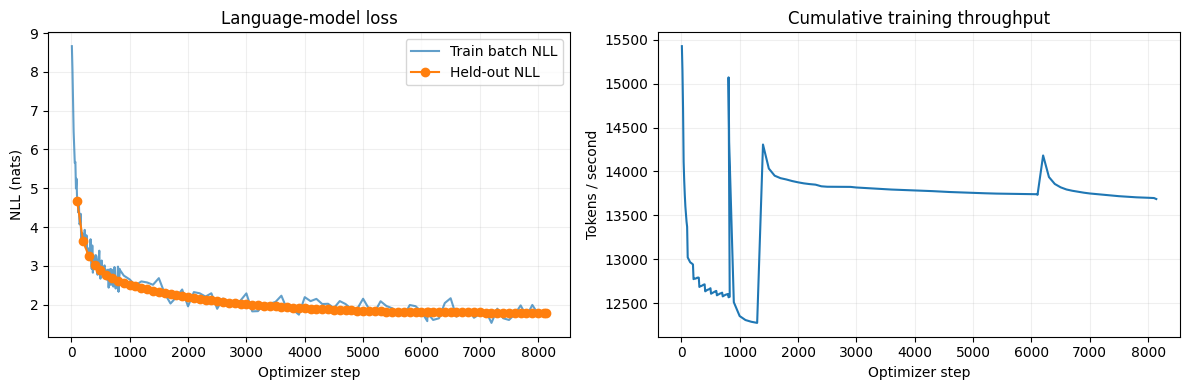

In [41]:
import matplotlib.pyplot as plt

logs = [json.loads(line) for line in (OUT / 'training.jsonl').read_text().splitlines() if line.strip()]
train_logs = [r for r in logs if 'train_loss' in r]
val_logs = [r for r in logs if 'val_loss' in r]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot([r['step'] for r in train_logs], [r['train_loss'] for r in train_logs], label='Train batch NLL', alpha=.7)
axes[0].plot([r['step'] for r in val_logs], [r['val_loss'] for r in val_logs], 'o-', label='Held-out NLL')
axes[0].set(xlabel='Optimizer step', ylabel='NLL (nats)', title='Language-model loss')
axes[0].legend()
axes[1].plot([r['step'] for r in train_logs], [r['tokens_per_second'] for r in train_logs])
axes[1].set(xlabel='Optimizer step', ylabel='Tokens / second', title='Cumulative training throughput')
for ax in axes:
    ax.grid(alpha=.2)
fig.tight_layout()
fig.savefig(OUT / 'learning_curves.png', dpi=160)
plt.show()

## Decoding comparison

In [42]:
distributed('infer.py', '--mode', 'dev')

import sacrebleu
from rouge_score import rouge_scorer

scorer = rouge_scorer.RougeScorer(['rougeL'], use_stemmer=True)
dev = json.loads((OUT / 'data' / 'dev.json').read_text())
references = {r['id']: {'text': r['reference']} for r in dev}
(OUT / 'dev_reference.json').write_text(json.dumps(references, ensure_ascii=False, indent=2))
metrics = []
for candidate in CFG['decoding_candidates']:
    merged = {}
    for rank in range(2):
        part = json.loads((OUT / f"dev_{candidate['name']}_rank{rank}.json").read_text())
        merged.update(part)
    hypotheses = [merged[r['id']]['text'] for r in dev]
    truths = [r['reference'] for r in dev]
    rouge = [scorer.score(ref, hyp)['rougeL'].fmeasure for ref, hyp in zip(truths, hypotheses)]
    bleu = sacrebleu.corpus_bleu(hypotheses, [truths])
    row = {'decoding': candidate, 'examples': len(dev), 'rougeL': sum(rouge) / len(rouge),
           'bleu': bleu.score, 'bleu_details': str(bleu),
           'source_rougeL': {s: sum(v for r, v in zip(dev, rouge) if r['source'] == s) /
                            max(1, sum(r['source'] == s for r in dev)) for s in CFG['source_mix']}}
    metrics.append(row)
    (OUT / f"dev_prediction_{candidate['name']}.json").write_text(json.dumps(merged, ensure_ascii=False, indent=2))
selected = max(metrics, key=lambda x: (x['rougeL'], x['bleu']))
(OUT / 'decoding_metrics.json').write_text(json.dumps(metrics, indent=2))
(OUT / 'selected_decoding.json').write_text(json.dumps(selected, indent=2))
for row in metrics:
    print(f"{row['decoding']['name']}: ROUGE-L={row['rougeL']:.4f}, BLEU={row['bleu']:.2f}")
print(f"Selected decoding: {selected['decoding']['name']}")
chosen_dev = json.loads((OUT / f"dev_prediction_{selected['decoding']['name']}.json").read_text())


dev/greedy GPU 1: 8/32
dev/greedy GPU 0: 8/32
dev/greedy GPU 1: 16/32
dev/greedy GPU 0: 16/32
dev/greedy GPU 1: 24/32
dev/greedy GPU 0: 24/32
dev/greedy GPU 1: 32/32
dev/greedy GPU 0: 32/32
dev/sample070 GPU 1: 8/32
dev/sample070 GPU 1: 16/32
dev/sample070 GPU 0: 8/32
dev/sample070 GPU 1: 24/32
dev/sample070 GPU 0: 16/32
dev/sample070 GPU 1: 32/32
dev/sample070 GPU 0: 24/32
dev/sample070 GPU 0: 32/32
greedy: ROUGE-L=0.3419, BLEU=22.89
sample070: ROUGE-L=0.3210, BLEU=22.23
Selected decoding: greedy


## Test continuations

In [43]:
from huggingface_hub import hf_hub_download

test_path = hf_hub_download(repo_id=CFG['repo'], repo_type='dataset',
                            filename=manifest['test_file'], revision=manifest['revision'],
                            token=os.environ['HF_TOKEN'])

with open(test_path, encoding='utf-8') as reader:
    test = json.load(reader)
(OUT / 'test.json').write_text(json.dumps(test, ensure_ascii=False))
print(f"Official test examples: {len(test)}")
distributed('infer.py', '--mode', 'test')

Official test examples: 1000
test/greedy GPU 1: 8/500
test/greedy GPU 0: 8/500
test/greedy GPU 0: 16/500
test/greedy GPU 1: 16/500
test/greedy GPU 0: 24/500
test/greedy GPU 1: 24/500
test/greedy GPU 1: 32/500
test/greedy GPU 0: 32/500
test/greedy GPU 1: 40/500
test/greedy GPU 0: 40/500
test/greedy GPU 0: 48/500
test/greedy GPU 1: 48/500
test/greedy GPU 0: 56/500
test/greedy GPU 1: 56/500
test/greedy GPU 1: 64/500
test/greedy GPU 0: 64/500
test/greedy GPU 0: 72/500
test/greedy GPU 1: 72/500
test/greedy GPU 0: 80/500
test/greedy GPU 1: 80/500
test/greedy GPU 1: 88/500
test/greedy GPU 0: 88/500
test/greedy GPU 0: 96/500
test/greedy GPU 1: 96/500
test/greedy GPU 0: 104/500
test/greedy GPU 1: 104/500
test/greedy GPU 0: 112/500
test/greedy GPU 1: 112/500
test/greedy GPU 0: 120/500
test/greedy GPU 1: 120/500
test/greedy GPU 0: 128/500
test/greedy GPU 1: 128/500
test/greedy GPU 0: 136/500
test/greedy GPU 1: 136/500
test/greedy GPU 0: 144/500
test/greedy GPU 1: 144/500
test/greedy GPU 0: 152/50

## Submission

In [44]:
import zipfile

predictions = {}
name = selected['decoding']['name']
for rank in range(2):
    part = json.loads((OUT / f'test_{name}_rank{rank}.json').read_text())
    predictions.update(part)
predictions = {key: predictions[key] for key in test}
prediction_path = OUT / 'prediction.json'
prediction_path.write_text(json.dumps(predictions, ensure_ascii=False, indent=2))
submission_path = OUT / 'submission.zip'
with zipfile.ZipFile(submission_path, 'w', zipfile.ZIP_DEFLATED) as archive:
    archive.write(prediction_path, arcname='prediction.json')


## Export

In [ ]:
from importlib.metadata import version
from IPython.display import FileLink, display

packages = ['torch', 'numpy', 'tokenizers', 'huggingface_hub', 'ijson', 'sacrebleu', 'rouge-score']
versions = {package: version(package) for package in packages}
(OUT / 'environment.json').write_text(json.dumps(versions, indent=2))
(OUT / 'requirements_used.txt').write_text('\n'.join(f'{k}=={v}' for k, v in versions.items()) + '\n')
readme = """LegalRoPE-204M(v2_increated_step)— Phase 1, submission 02 
18 layers, width 896, 14 heads, SwiGLU 2432, RoPE, RMSNorm, tied embeddings.
legal-corpus byte-level BPE.
Load best.pt with weights_only=True and instantiate LegalLM(checkpoint['config']).
Load its model state and use the matching tokenizer.json.
"""
(OUT / 'README.txt').write_text(readme)
export_names = ['best.pt', 'tokenizer.json', 'model.py', 'prepare.py', 'train.py', 'infer.py',
                'config.json', 'model_config.json',
                'training_summary.json', 'training.jsonl', 'decoding_metrics.json',
                'selected_decoding.json', 'learning_curves.png', 'environment.json',
                'requirements_used.txt', 'README.txt', 'data/manifest.json']
with zipfile.ZipFile(OUT / 'model_bundle.zip', 'w', zipfile.ZIP_DEFLATED, compresslevel=1) as archive:
    for filename in export_names:
        path = OUT / filename
        archive.write(path, arcname=filename)
for filename in ['submission.zip', 'model_bundle.zip', 'learning_curves.png', 'training_summary.json']:
    display(FileLink(filename))
